In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
pip install Bio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 29.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [Bio]


In [ ]:
import requests

folder = '/content/drive/MyDrive/Math_Modelling_lab/Bioinformatics'

dataset = {
  "P68871": "HBB_HUMAN",
  "P69905": "HBA_HUMAN",
  "P02144": "MB_HUMAN",
  "P02185": "MB_PHYMC",
  "P02088": "HBB_MOUSE",
  "P02024": "HBB_GORGO",
  "P02062": "HBB_HORSE",
  "P0DTC2": "SPIKE_SARS2",
  "P59594": "SPIKE_SARS1",
  "K9N5Q8": "SPIKE_MERS"
}

for uniprot_id, name in dataset.items():
  url = f"https://rest.uniprot.org/uniprotkb/{uniprot_id}.fasta"
  response = requests.get(url)
  with open(f"{folder}/{name}.fasta", "w") as file:
      file.write(response.text)
  print(f"Downloaded {name} ({uniprot_id})")

print("\nDownload complete!")

Downloaded HBB_HUMAN (P68871)
Downloaded HBA_HUMAN (P69905)
Downloaded MB_HUMAN (P02144)
Downloaded MB_PHYMC (P02185)
Downloaded HBB_MOUSE (P02088)
Downloaded HBB_GORGO (P02024)
Downloaded HBB_HORSE (P02062)
Downloaded SPIKE_SARS2 (P0DTC2)
Downloaded SPIKE_SARS1 (P59594)
Downloaded SPIKE_MERS (K9N5Q8)

Download complete!


In [ ]:
from Bio import SeqIO

dataset = {
  "P68871": "HBB_HUMAN",
  "P69905": "HBA_HUMAN",
  "P02144": "MB_HUMAN",
  "P02185": "MB_PHYMC",
  "P02088": "HBB_MOUSE",
  "P02024": "HBB_GORGO",
  "P02062": "HBB_HORSE",
  "P0DTC2": "SPIKE_SARS2",
  "P59594": "SPIKE_SARS1",
  "K9N5Q8": "SPIKE_MERS"
}

sequence = {}
names = dataset.values()

for name in names:
  record = SeqIO.read(f"/content/drive/MyDrive/Math_Modelling_lab/Bioinformatics/{name}.fasta", "fasta")
  sequence[name] = record.seq

print(sequence)

{'HBB_HUMAN': Seq('MVHLTPEEKSAVTALWGKVNVDEVGGEALGRLLVVYPWTQRFFESFGDLSTPDA...KYH'), 'HBA_HUMAN': Seq('MVLSPADKTNVKAAWGKVGAHAGEYGAEALERMFLSFPTTKTYFPHFDLSHGSA...KYR'), 'MB_HUMAN': Seq('MGLSDGEWQLVLNVWGKVEADIPGHGQEVLIRLFKGHPETLEKFDKFKHLKSED...FQG'), 'MB_PHYMC': Seq('MVLSEGEWQLVLHVWAKVEADVAGHGQDILIRLFKSHPETLEKFDRFKHLKTEA...YQG'), 'HBB_MOUSE': Seq('MVHLTDAEKAAVSCLWGKVNSDEVGGEALGRLLVVYPWTQRYFDSFGDLSSASA...KYH'), 'HBB_GORGO': Seq('MVHLTPEEKSAVTALWGKVNVDEVGGEALGRLLVVYPWTQRFFESFGDLSTPDA...KYH'), 'HBB_HORSE': Seq('VQLSGEEKAAVLALWDKVNEEEVGGEALGRLLVVYPWTQRFFDSFGDLSNPGAV...KYH'), 'SPIKE_SARS2': Seq('MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSSVLHSTQDL...HYT'), 'SPIKE_SARS1': Seq('MFIFLLFLTLTSGSDLDRCTTFDDVQAPNYTQHTSSMRGVYYPDEIFRSDTLYL...HYT'), 'SPIKE_MERS': Seq('MIHSVFLLMFLLTPTESYVDVGPDSVKSACIEVDIQQTFFDKTWPRPIDVSKAD...HVH')}


In [ ]:
print(sequence['HBB_HUMAN'])

#Q2

(a) Formulate the dynamic programming recurrence relation for global sequence alignment
using a match score of (+1), mismatch score of (-1) and gap penalty of (-1). Implement the
algorithm in Python by initialising and filling the score matrix and storing traceback information.

(b) Apply traceback to obtain an optimal global alignment and its score. Display the aligned
sequences in blocks of 60 characters, using | to indicate identical residues.

In [ ]:
import numpy as np

def needleman_wunch(seq1, seq2, MATCH, MISMATCH, GAP):
    m,n = len(seq1), len(seq2)

    # Initialise score matrix
    T = np.zeros((m + 1, n + 1), dtype=int)

    # Store traceback directions
    traceback = np.zeros((m + 1, n + 1), dtype=int)

    # Direction codes: 1 = diagonal, 2 = up, 3 = left
    for i in range(1, m + 1):
        T[i, 0] = i * GAP
        traceback[i, 0] = 2
    for j in range(1, n + 1):
        T[0, j] = j * GAP
        traceback[0, j] = 3

    # Fill in the DP table
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            diagonal = T[i-1, j-1] + (
                MATCH if seq1[i - 1] == seq2[j - 1]
                else MISMATCH
            )
            up = T[i-1, j] + GAP
            left = T[i, j-1] + GAP

            T[i, j] = max(diagonal, up, left)

            # Store one optimal direction
            if T[i, j] == diagonal:
                traceback[i, j] = 1
            elif T[i, j] == up:
                traceback[i, j] = 2
            else:
                traceback[i, j] = 3

    # Traceback
    aligned1, aligned2 = [], []
    score = T[m, n]
    i, j = m, n

    while i > 0 or j > 0:
        direction = traceback[i, j]

        if i > 0 and j > 0 and direction == 1:
            aligned1.append(seq1[i - 1])
            aligned2.append(seq2[j - 1])
            i -= 1
            j -= 1

        elif i > 0 and (j == 0 or direction == 2):
            aligned1.append(seq1[i - 1])
            aligned2.append("-")
            i -= 1

        else:
            aligned1.append("-")
            aligned2.append(seq2[j - 1])
            j -= 1

    aligned1 = "".join(reversed(aligned1))
    aligned2 = "".join(reversed(aligned2))

    return T, traceback, aligned1, aligned2, score

In [ ]:
def display_alignment(alignment_1, alignment_2):
    print(alignment_1)
    for i in range(len(alignment_1)):
        if alignment_1[i] == alignment_2[i] and alignment_1[i]!='-':
            print("|", end = "")
        else:
            print(" ", end = "")
    print()
    print(alignment_2)

In [ ]:
T, traceback, aligned1, aligned2, score = needleman_wunch("GATTACA", "GCATGCU", 1, -1, -1)
print(T)
print(traceback)
display_alignment(aligned1, aligned2)
print(score)

[[ 0 -1 -2 -3 -4 -5 -6 -7]
 [-1  1  0 -1 -2 -3 -4 -5]
 [-2  0  0  1  0 -1 -2 -3]
 [-3 -1 -1  0  2  1  0 -1]
 [-4 -2 -2 -1  1  1  0 -1]
 [-5 -3 -3 -1  0  0  0 -1]
 [-6 -4 -2 -2 -1 -1  1  0]
 [-7 -5 -3 -1 -2 -2  0  0]]
[[0 3 3 3 3 3 3 3]
 [2 1 3 3 3 1 3 3]
 [2 2 1 1 3 3 3 3]
 [2 2 1 2 1 3 3 3]
 [2 2 1 2 1 1 1 1]
 [2 2 1 1 2 1 1 1]
 [2 2 1 2 2 1 1 3]
 [2 2 2 1 2 1 2 1]]
G-ATTACA
| | | | 
GCA-TGCU
0


(c) Validate the implementation using the following sequence pairs:
* GATTACA and GATTACA: expected score (7).
* GATTACA and GCATGCU: expected score (0).
* AAAA and TTTT: expected score (-4).

Verify that swapping the two sequences preserves the optimal alignment score.
Visualise the dynamic programming score matrix as a heatmap and overlay the optimal
traceback path for any one selected pair.

In [ ]:
MATCH = 1
MISMATCH = -1
GAP = -1

_, _, aligned1, aligned2, score = needleman_wunch("GATTACA", "GATTACA", MATCH, MISMATCH, GAP)
display_alignment(aligned1, aligned2)
print("Score:", score, "\n")

_, _, aligned1, aligned2, score = needleman_wunch("AAAA", "TTTT", MATCH, MISMATCH, GAP)
display_alignment(aligned1, aligned2)
print("Score:", score, "\n")

T, traceback, aligned1, aligned2, score = needleman_wunch("GATTACA", "GCATGCU", MATCH, MISMATCH, GAP)
display_alignment(aligned1, aligned2)
print("Score:", score, "\n")

GATTACA
|||||||
GATTACA
Score: 7 

AAAA
    
TTTT
Score: -4 

G-ATTACA
| | | | 
GCA-TGCU
Score: 0 



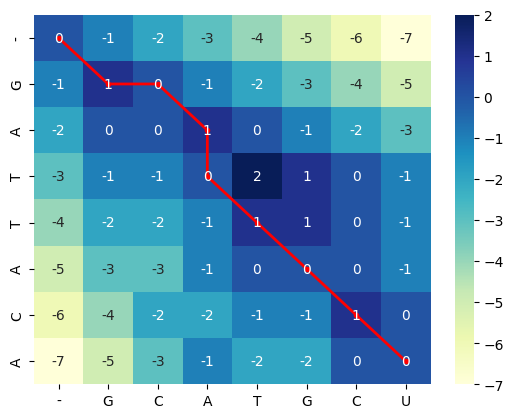

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

def visualise_global_alignment(seq1, seq2, T, traceback):
  ax = sns.heatmap(
        T,
        cmap="YlGnBu",
        annot=True if max(len(seq1), len(seq2)) <= 15 else False,
        fmt="d",
        xticklabels=["-"] + list(seq2),
        yticklabels=["-"] + list(seq1)
  )

  # Reconstruct traceback coordinates
  i, j = len(seq1), len(seq2)
  path_i = [i]
  path_j = [j]

  while i > 0 or j > 0:
    direction = traceback[i, j]
    if i > 0 and j > 0 and direction == 1:
        i -= 1
        j -= 1
    elif i > 0 and (j == 0 or direction == 2):
        i -= 1
    else:
        j -= 1

    path_i.append(i)
    path_j.append(j)

  # Heatmap coordinates use cell centres
  ax.plot(
    np.array(path_j) + 0.5,
    np.array(path_i) + 0.5,
    color="red",
    linewidth=2,
    marker="o",
    markersize=3
  )

plt.show()


visualise_global_alignment("GATTACA", "GCATGCU", T, traceback)

(d) Align human HBB with the other HBB sequences in Table 1 and with human myoglobin.
Calculate the alignment score, percentage identity and number of gaps for each pair. Present
the results in a table and rank the sequences according to percentage identity.

Percentage Identity = (Number of matches / Total Alignment length) * 100

In [ ]:
import pandas as pd

hbb_seq_name = ['HBB_MOUSE','HBB_GORGO','HBB_HORSE','MB_HUMAN']
human_hbb = sequence['HBB_HUMAN']
results = []

for name in hbb_seq_name:
  _, _, aligned1, aligned2, score = needleman_wunch(human_hbb, sequence[name], MATCH, MISMATCH, GAP)

  identical = sum(x == y and x != "-" for x, y in zip(aligned1, aligned2))
  gaps = sum(x == "-" or y == "-" for x, y in zip(aligned1, aligned2))

  identity = 100 * identical / len(aligned1)

  results.append({
    "Protein": name,
    "Alignment Score": score,
    "Identity (%)": round(identity, 2),
    "Number of Gaps": gaps,
  })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("Identity (%)", ascending=False).reset_index(drop=True)
results_df

,Protein,Alignment Score,Identity (%),Number of Gaps
0,HBB_GORGO,145,99.32,0
1,HBB_HORSE,97,82.99,1
2,HBB_MOUSE,89,80.27,0
3,MB_HUMAN,-62,31.33,31


#Q3

The Smith–Waterman algorithm identifies the most similar local regions between two biological sequences.

(a) Formulate and implement the Smith–Waterman recurrence relation using a match score of (+3), mismatch score of (-3) and gap penalty of (-2). Initialise the first row and column to zero and include zero as a candidate score in each cell.

(b) Identify the maximum-scoring cell and perform traceback until a cell with score zero is
reached. Report the local alignment, its score and the corresponding start and end positions in
both sequences.

In [ ]:
import numpy as np

def smith_waterman(seq1, seq2, MATCH, MISMATCH, GAP):
    m,n = len(seq1), len(seq2)

    # Initialise score matrix
    T = np.zeros((m + 1, n + 1), dtype=int)

    # Store traceback directions
    traceback = np.zeros((m + 1, n + 1), dtype=int)

    # Fill in the DP table
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            diagonal = T[i-1, j-1] + (
                MATCH if seq1[i - 1] == seq2[j - 1]
                else MISMATCH
            )
            up = T[i-1, j] + GAP
            left = T[i, j-1] + GAP

            T[i, j] = max(diagonal, up, left, 0)

            # Store one optimal direction --> 1 = diagonal, 2 = up, 3 = left
            if T[i, j] == 0:
                traceback[i, j] = 0
            elif T[i, j] == diagonal:
                traceback[i, j] = 1
            elif T[i, j] == up:
                traceback[i, j] = 2
            else:
                traceback[i, j] = 3

    # Traceback
    aligned1, aligned2 = [], []
    i_max, j_max = np.unravel_index(np.argmax(T), T.shape)      # Find the maximum score and its coordinates
    i, j = i_max, j_max
    score = T[i_max, j_max]

    # Traceback
    aligned1, aligned2 = [], []

    while i > 0 and j > 0 and T[i, j] > 0:
        direction = traceback[i, j]

        if direction == 1:
            aligned1.append(seq1[i - 1])
            aligned2.append(seq2[j - 1])
            i -= 1
            j -= 1

        elif direction == 2:
            aligned1.append(seq1[i - 1])
            aligned2.append("-")
            i -= 1

        elif direction == 3:
            aligned1.append("-")
            aligned2.append(seq2[j - 1])
            j -= 1

    aligned1 = "".join(reversed(aligned1))
    aligned2 = "".join(reversed(aligned2))

    return T, traceback, aligned1, aligned2, score

(c) Validate the implementation using TGTTACGG and GGTTGACTA. Verify that the maximum local alignment score is (13) under the specified scoring scheme. Plot the Smith–Waterman score matrix as a heatmap and mark the maximum-scoring cell and traceback path.

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

def visualise_local_alignment(seq1, seq2, T, traceback):
  ax = sns.heatmap(
        T,
        cmap="YlGnBu",
        annot=True if max(len(seq1), len(seq2)) <= 15 else False,
        fmt="d",
        xticklabels=["-"] + list(seq2),
        yticklabels=["-"] + list(seq1)
  )

  # Reconstruct traceback coordinates
  i, j = np.unravel_index(np.argmax(T), T.shape)
  path_i = [i]
  path_j = [j]

  while i > 0 and j > 0 and T[i, j] > 0:
    direction = traceback[i, j]
    if direction == 1:       # Diagonal
        i -= 1
        j -= 1
    elif direction == 2:     # Up
        i -= 1
    elif direction == 3:     # Left
        j -= 1
    else:
        break

    path_i.append(i)
    path_j.append(j)

  # Heatmap coordinates use cell centres
  ax.plot(
    np.array(path_j) + 0.5,
    np.array(path_i) + 0.5,
    color="red",
    linewidth=2,
    marker="o",
    markersize=3
  )

plt.show()

GTT-AC
||| ||
GTTGAC
Score: 13 



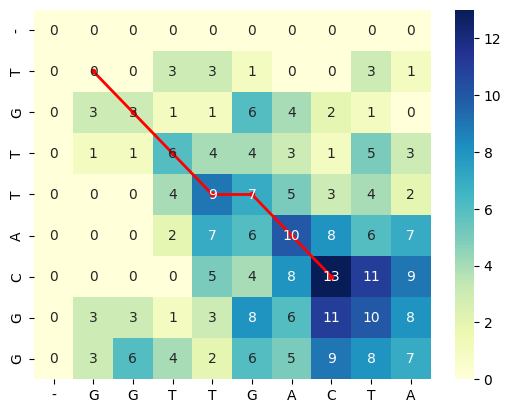

In [ ]:
MATCH = 3
MISMATCH = -3
GAP = -2

T, traceback, aligned1, aligned2, score = smith_waterman("TGTTACGG", "GGTTGACTA", MATCH, MISMATCH, GAP)
display_alignment(aligned1, aligned2)
print("Score:", score, "\n")

visualise_local_alignment("TGTTACGG", "GGTTGACTA", T, traceback)

(d) Use residues 319–541 of the SARS-CoV-2 spike protein as the query and identify the best local alignment within the SARS-CoV and MERS-CoV spike proteins. Report the alignment, alignment score, percentage identity.

In [ ]:
sars_cov_2, sars_cov, mers_cov = sequence['SPIKE_SARS2'], sequence['SPIKE_SARS1'], sequence['SPIKE_MERS']

_, _, aligned1, aligned2, score = smith_waterman(sars_cov_2[318:541], sars_cov, MATCH, MISMATCH, GAP)
print("Alignment between SARS-Cov-2 and SARS-CoV proteins")
print("Alignment Score:", score)
print("Alignment length: ", len(aligned1))
display_alignment(aligned1, aligned2)
identical = sum(
    a == b and a != "-"
    for a, b in zip(aligned1, aligned2)
)
identity = 100 * identical / len(aligned1)
print("Percentage identity:", round(identity, 2), "%")


_, _, aligned1, aligned2, score = smith_waterman(sars_cov_2[318:541], mers_cov, MATCH, MISMATCH, GAP)
print("\nAlignment between SARS-Cov-2 and MERS-CoV proteins")
print("Alignment Score:", score)
print("Alignment length: ", len(aligned1))
display_alignment(aligned1, aligned2)
identical = sum(
    a == b and a != "-"
    for a, b in zip(aligned1, aligned2)
)
identity = 100 * identical / len(aligned1)
print("Percentage identity:", round(identity, 2), "%")

Alignment between SARS-Cov-2 and SARS-CoV proteins
Alignment Score: 334
Alignment length:  221
VRFPNITNLCPFGEVFNATRFASVYAWNRKRISNCVADYSVLYNSASFSTFKCYGVSPTKLNDLCFTNVYADSFVIRGDEVRQIAPGQTGKIADYNYKLPDDFTGCVIAWNSNNLD--SKVGGNYNYLYR-LFR--KSNLKPFERDIS-TEIYQAGSTPCNGVEGFNCYFPLQSYGFQPTNGVGYQPYRVVVLSFELLHAPATVCGPKKSTNLVKNKCVNF
||||||||||||||||||| | ||||| || ||||||||||||||  |||||||||| |||||||| ||||||||  || |||||||||| |||||||||||| ||| |||  | |  |   ||||| || | |  |  | |||||||       |  ||      ||| ||  |||  | | ||||||||||||||| ||||||||| || | || ||||
VRFPNITNLCPFGEVFNATKFPSVYAWERKKISNCVADYSVLYNSTFFSTFKCYGVSATKLNDLCFSNVYADSFVVKGDDVRQIAPGQTGVIADYNYKLPDDFMGCVLAWNTRNIDATS--TGNYNYKYRYL-RHGK--LRPFERDISNVPFSPDG-KPC-TPPALNCYWPLNDYGFYTTTGIGYQPYRVVVLSFELLNAPATVCGPKLSTDLIKNQCVNF
Percentage identity: 74.21 %

Alignment between SARS-Cov-2 and MERS-CoV proteins
Alignment Score: 14
Alignment length:  8
NI-TNLCP
|| ||| |
NISTNL-P
Percentage identity: 75.0 %


(e) Apply both global and local alignment to the SARS-CoV-2 and SARS-CoV spike proteins. Compare their scores, alignment lengths and percentage identities. Explain why the two methods may produce different results and identify the biological questions each method can answer.

In [ ]:
_, _, aligned1, aligned2, score = needleman_wunch(sars_cov_2, sars_cov, MATCH, MISMATCH, GAP)
print("Global Alignment between SARS-CoV-2 and SARS-CoV proteins")
print("Alignment Score:", score)
print("Alignment length: ", len(aligned1))
display_alignment(aligned1, aligned2)
identical = sum(
    a == b and a != "-"
    for a, b in zip(aligned1, aligned2)
)
identity = 100 * identical / len(aligned1)
print("Percentage identity:", round(identity, 2), "%")


_, _, aligned1, aligned2, score = smith_waterman(sars_cov_2, sars_cov, MATCH, MISMATCH, GAP)
print("\nLocal Alignment between SARS-CoV-2 and SARS-CoV proteins")
print("Alignment Score:", score)
print("Alignment length: ", len(aligned1))
display_alignment(aligned1, aligned2)
identical = sum(
    a == b and a != "-"
    for a, b in zip(aligned1, aligned2)
)
identity = 100 * identical / len(aligned1)
print("Percentage identity:", round(identity, 2), "%")

Global Alignment between SARS-CoV-2 and SARS-CoV proteins
Alignment Score: 2168
Alignment length:  1304
MFVFLVL-LPLVS-S---QCVNLTT--RTQLPPAYT--NSFTRGVYYPDKVFRSSVLHSTQDLFLPFFSNVTWFHAIHVSGTNGTKRFDNPVLPFNDGVYFASTEKSNIIRGWIFGTTLDSKTQSLLIVNNATNVVIKVCEFQFC-NDPFLGVYYHK---NNKSWMESEFRVYSSANNCTFEYVSQPF-LMD-LEGKQGNFKNLREFVFKNIDGYFKIY-SK-HTPINLVRDLPQGFSALEPLVDLPIGINITRF-QTLLALHRSYLTP-GDSSSGWTAGAAAYYVGYLQPRTFLLKYNENGTITDAVDCALDPLSETKCTLKSFTVE--KGIYQTSNFRVQPTES--IVRFPNITNLCPFGEVFNATRFASVYAWNRKRISNCVADYSVLYNSASFSTFKCYGVSPTKLNDLCFTNVYADSFVIRGDEVRQIAPGQTGKIADYNYKLPDDFTGCVIAWNSNNLD--SKVGGNYNYLYR-LFR--KSNLKPFERDIS-TEIYQAGSTPCNGVEGFNCYFPLQSYGFQPTNGVGYQPYRVVVLSFELLHAPATVCGPKKSTNLVKNKCVNFNFNGLTGTGVLTESNKKFLPFQQFGRDIADTTDAVRDPQTLEILDITPCSFGGVSVITPGTNTSNQVAVLYQDVNCTEVPVAIHADQLTPTWRVYSTGSNVFQTRAGCLIGAEHVNNSYECDIPIGAGICASYQTQTNSPRRARSVASQ-SIIAYTMSLGAENSVAYSNNSIAIPTNFTISVTTEILPVSMTKTSVDCTMYICGDSTECSNLLLQYGSFCTQLNRALTGIAVEQDKNTQEVFAQVKQIYKTPPIKDFGGFNFSQILPDPSKPSKRSFIEDLLFNKVTLADAGFIKQYGDCLGDIAARDLICAQKFNGLTVLPPLLT

In [ ]:
# Global alignment must account for the entire sequences, including divergent regions and terminal gaps.
# Local alignment can exclude poorly matching regions and retain a high-scoring region. Therefore, it can achieve a higher score even though it aligns fewer positions.

#Q1

A dot matrix plot is a simple visual method for comparing two sequences. It shows matches, repeats, insertions/deletions and inverted repeats, but it gives no alignment score.

(a) Implement a dot matrix function with a word size w (a dot is placed only if w consecutive residues match). Plot the result with sequence A along the x-axis and sequence B along the y-axis. Validate it with the following cases:
* ATGGCATC vs GTGGCAGT: the diagonal must reveal the shared run TGGCA.
* TTAGTTAGTTAG vs itself: parallel diagonals must appear for the repeated motif TTAG.
* ATGGCTAACGTTAC vs ATGGCTTTAC: the diagonal must be interrupted or shifted, showing an indel.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def dot_matrix(seq1, seq2, w=1):
    m, n = len(seq2), len(seq1)
    D = np.zeros((m, n), dtype=int)
    for i in range(m - w + 1):
        for j in range(n - w + 1):
            if seq2[i:i+w] == seq1[j:j+w]:
                D[i, j] = 1
    return D


def visualise_dot_matrix(D, seq1, seq2, title):
  plt.figure(figsize=(6, 6))
  plt.imshow(D, cmap="Greys", aspect="auto", origin="upper")
  plt.xlabel("Sequence 1 position")
  plt.ylabel("Sequence 2 position")
  plt.title(title)
  plt.colorbar(label="Match (1) / No match (0)")
  plt.tight_layout()
  plt.show()

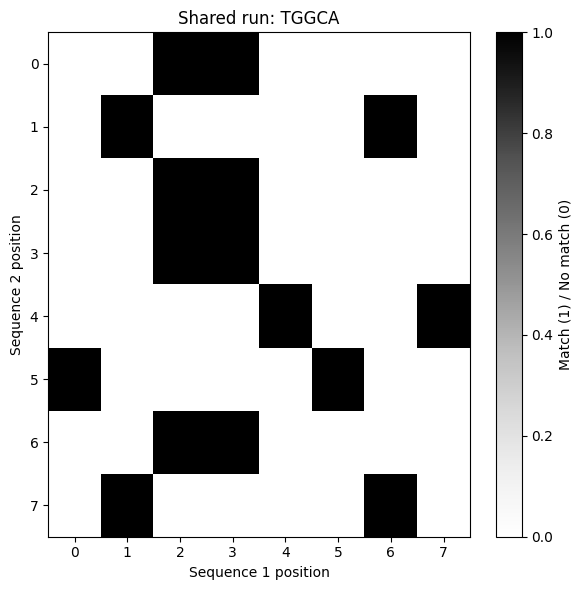

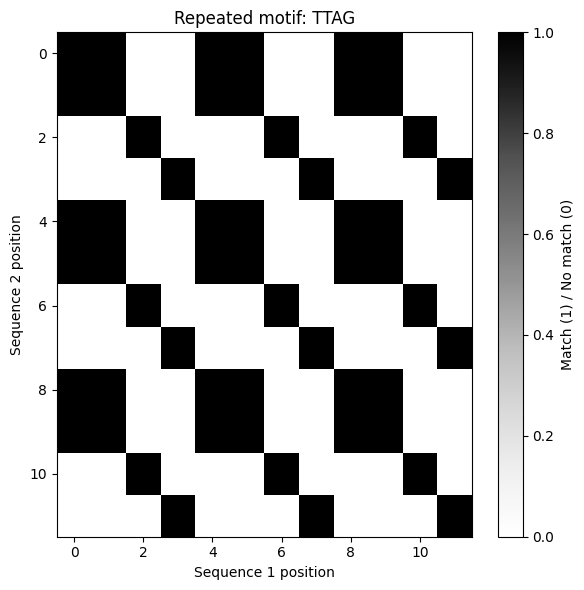

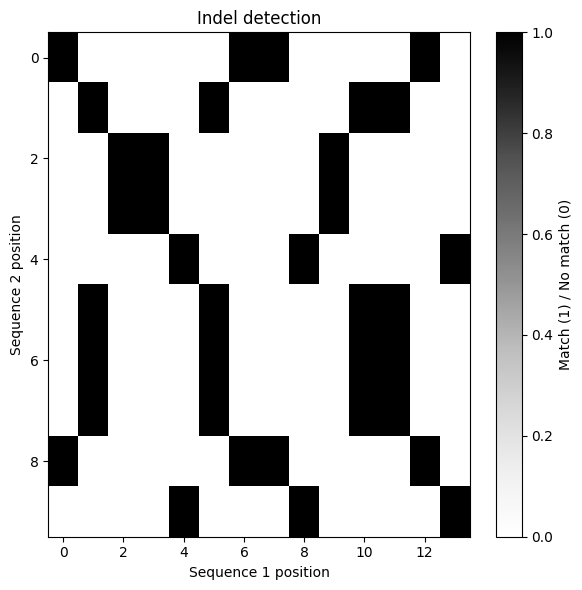

In [ ]:
# Case 1: Shared run TGGCA
A = "ATGGCATC"
B = "GTGGCAGT"
D = dot_matrix(A, B)
visualise_dot_matrix(D, A, B, "Shared run: TGGCA")

# Case 2: Repeated motif TTAG
A = "TTAGTTAGTTAG"
B = A
D = dot_matrix(A, B)
visualise_dot_matrix(D, A, B, "Repeated motif: TTAG")

# Case 3: Indel
A = "ATGGCTAACGTTAC"
B = "ATGGCTTTAC"
D = dot_matrix(A, B)
visualise_dot_matrix(D, A, B, "Indel detection")

(b) Plot HBB_HUMAN against (i) itself, (ii) HBB_MOUSE and (iii) HBA_HUMAN, with word sizes 1, 3 and 5. Count the number of dots for each plot. Explain how increasing the word size filters out random matches.

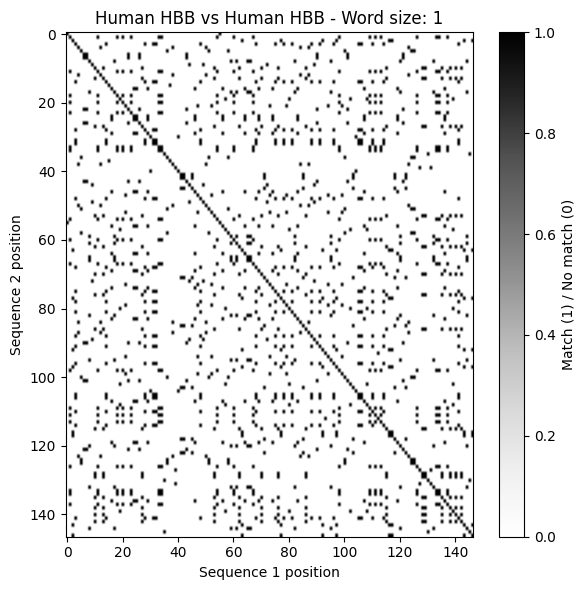

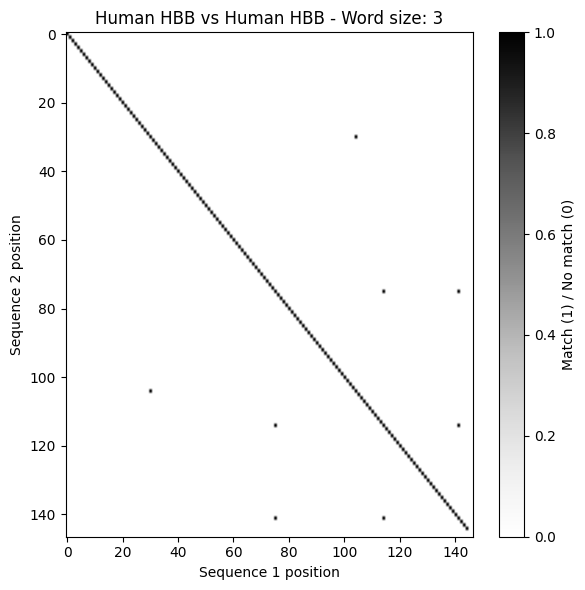

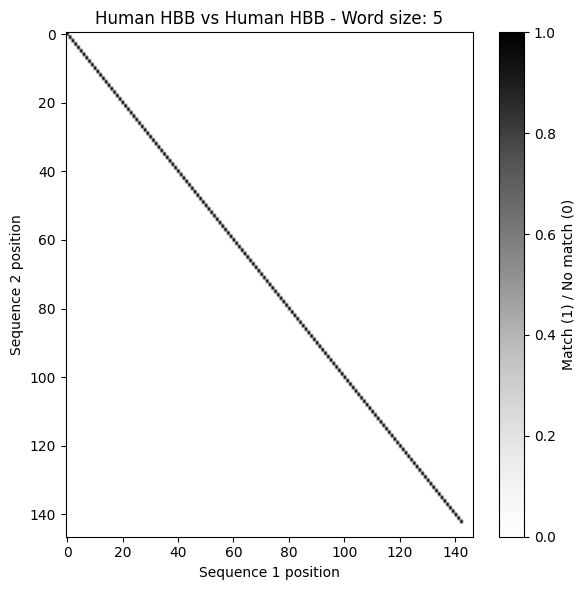

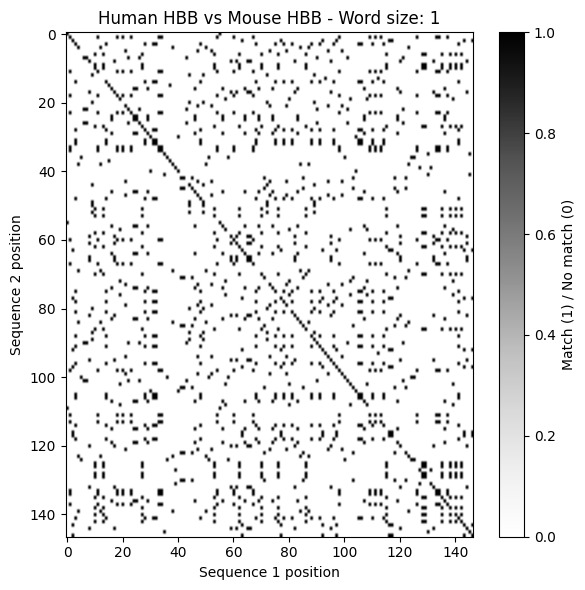

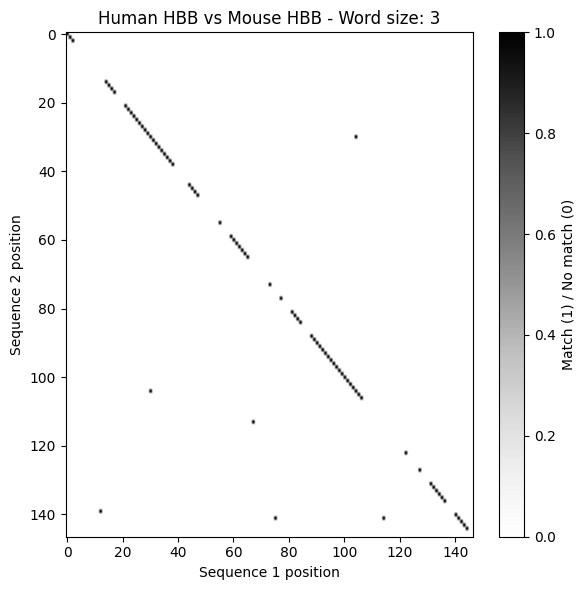

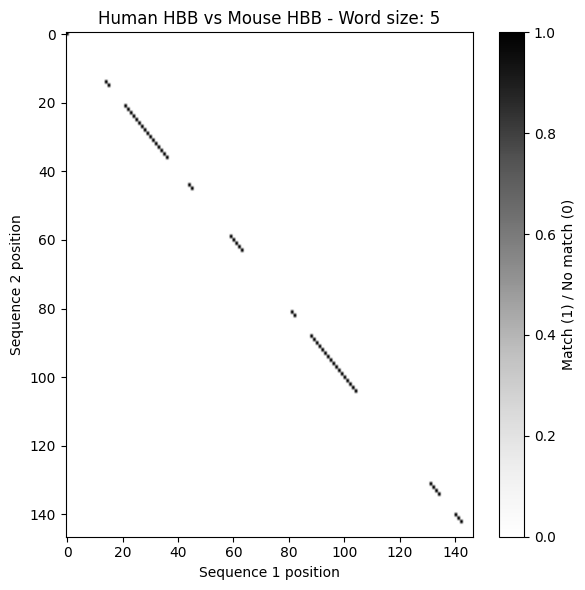

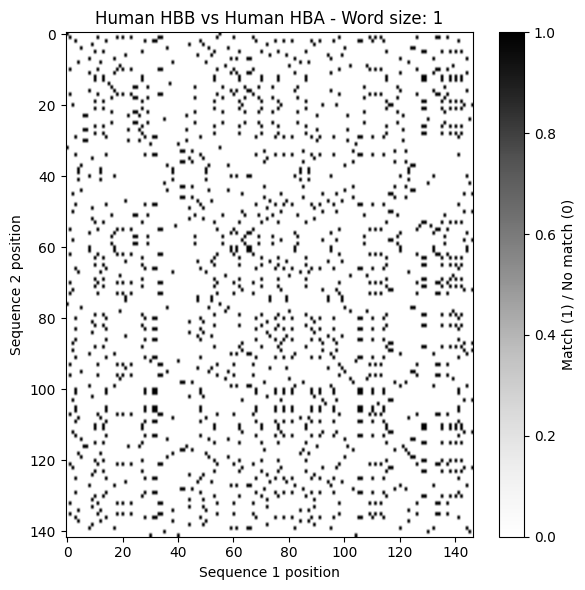

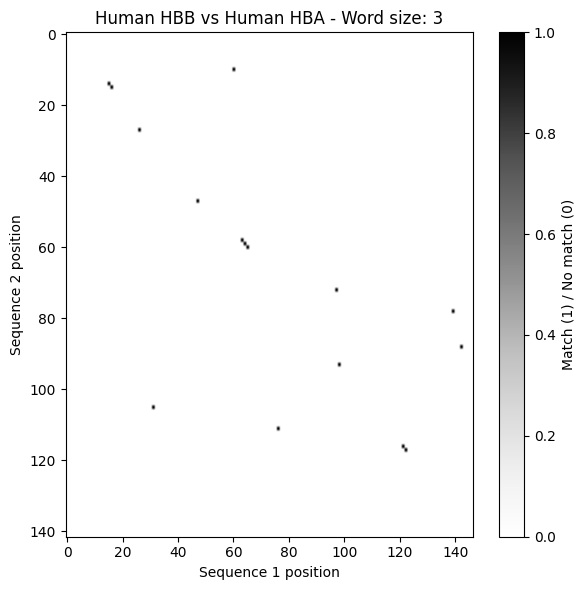

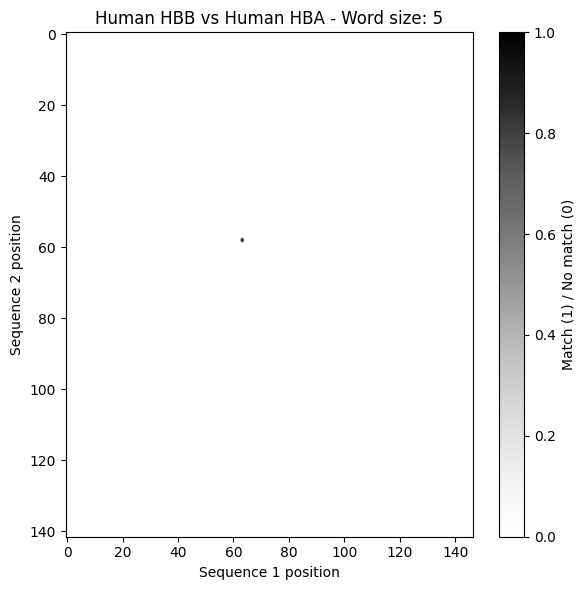

In [ ]:
hbb_human = sequence['HBB_HUMAN']

word_sizes = [1, 3, 5]
comparisons = {
    "Human HBB vs Human HBB": hbb_human,
    "Human HBB vs Mouse HBB": sequence["HBB_MOUSE"],
    "Human HBB vs Human HBA": sequence["HBA_HUMAN"]
}

for name,seq in comparisons.items():
  for w in word_sizes:
    D = dot_matrix(hbb_human, seq, w)
    visualise_dot_matrix(D, hbb_human, seq, f"{name} - Word size: {w}")

(c) Plot SARS-CoV-2 spike against SARS-CoV spike and against MERS-CoV spike, using a suitable word size or window and threshold. Mark residues 319–541 (the query region used in Question 3(d)). Find the longest continuous diagonal in each plot and compare how well the two diagonals are conserved.

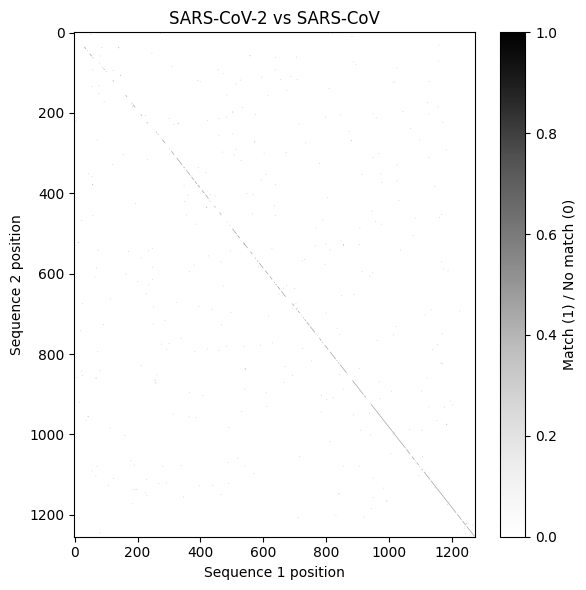

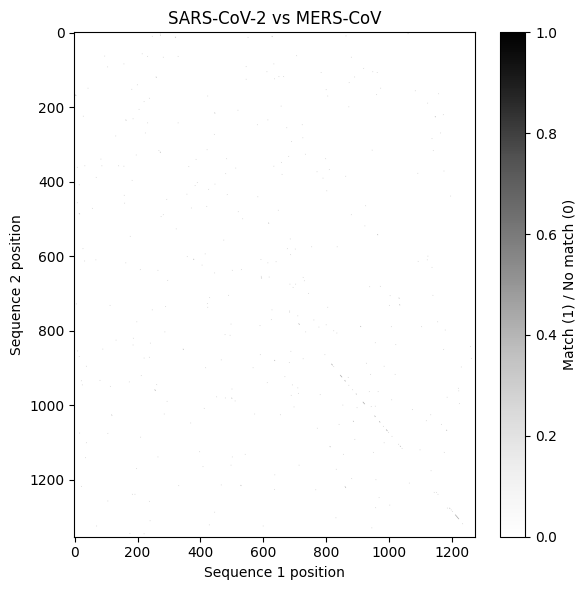

In [ ]:
sars_cov_2 = sequence['SPIKE_SARS2']
sars_cov = sequence['SPIKE_SARS1']
mers_cov = sequence['SPIKE_MERS']

word_size = 3
D_1 = dot_matrix(sars_cov_2, sars_cov, word_size)
visualise_dot_matrix(D_1, sars_cov_2, sars_cov, "SARS-CoV-2 vs SARS-CoV")

D_2 = dot_matrix(sars_cov_2, mers_cov, word_size)
visualise_dot_matrix(D_2, sars_cov_2, mers_cov, "SARS-CoV-2 vs MERS-CoV")

(d) Compare TGCAAGCTTGCA with its own complement (using the reverse complement) and plot the result. Identify the off-diagonal line and state whether the sequence is a palindrome or an inverted repeat. Also compare TACCGGCCAT with itself and describe the palindromic pattern.

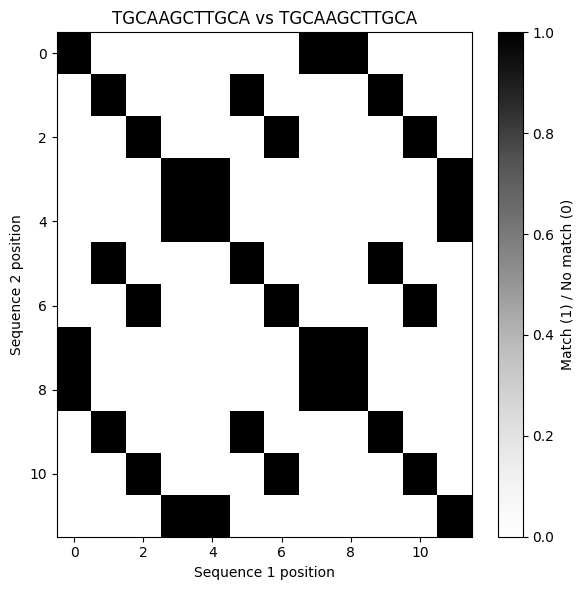

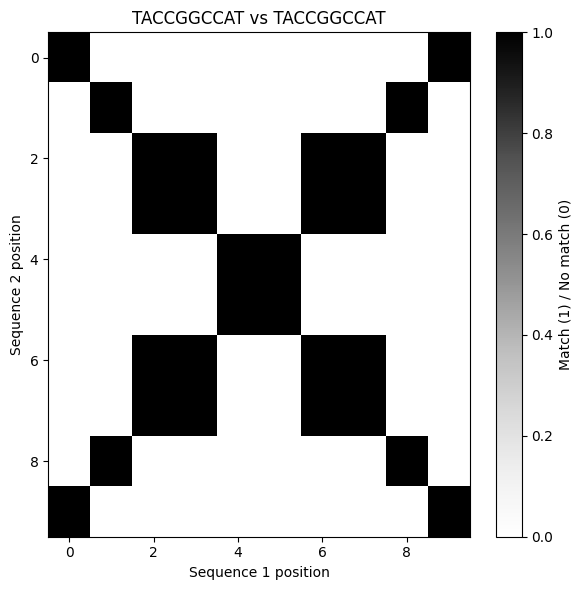

In [ ]:
from Bio.Seq import Seq

seq1 = "TGCAAGCTTGCA"
seq2 = str(Seq(seq1).reverse_complement())

D = dot_matrix(seq1, seq2)
visualise_dot_matrix(D, seq1, seq2, f"{seq1} vs {seq2}")

seq = "TACCGGCCAT"
D = dot_matrix(seq, seq)
visualise_dot_matrix(D, seq, seq, f"{seq} vs {seq}")

# Interpretation
# TGCAAGCTTGCA: reverse complement is the same as the original
# TACCGGCCAT: palindrome (same as its reverse complement)

(e) Compare the dot plots with your global and local alignments from Questions 2 and 3. State what the dot plot shows that is easy to see, and what it cannot report (score, actual alignment). Say which of the three methods you would use first for an unknown pair of sequences, and why.

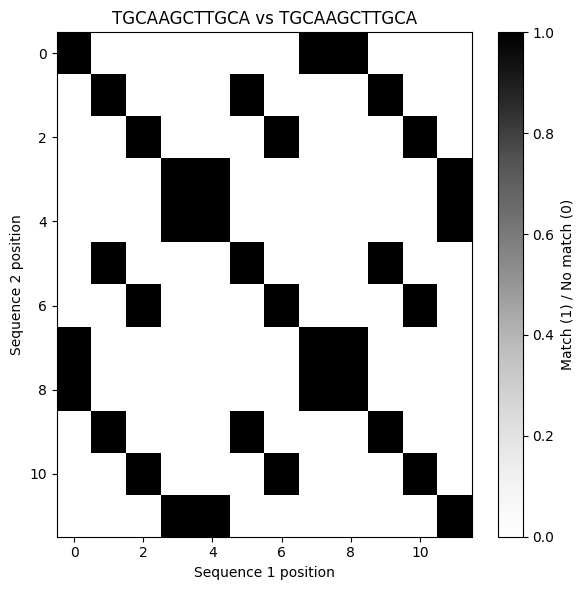

Global alignment: 
TGCAAGCTTGCA
||||||||||||
TGCAAGCTTGCA
Score: 36

Local alignment: 
TGCAAGCTTGCA
||||||||||||
TGCAAGCTTGCA
Score: 36


In [ ]:
seq1 = "TGCAAGCTTGCA"
seq2 = str(Seq(seq1).reverse_complement())
D = dot_matrix(seq1, seq2)
visualise_dot_matrix(D, seq1, seq2, f"{seq1} vs {seq2}")

print("Global alignment: ")
_,_,a1,a2,score = needleman_wunch(seq1, seq2, MATCH, MISMATCH, GAP)
display_alignment(a1, a2)
print("Score:", score)

print("\nLocal alignment: ")
_,_,a1,a2,score = smith_waterman(seq1, seq2, MATCH, MISMATCH, GAP)
display_alignment(a1, a2)
print("Score:", score)

#Q4

Study how different substitution matrices affect the global alignment of protein sequences using Biopython.

(a) Load the PAM30, PAM250, BLOSUM45, BLOSUM62 and BLOSUM80 substitution matrices using Biopython. Display the BLOSUM62 matrix as a heatmap and identify the residue pairs with the highest and lowest substitution scores.

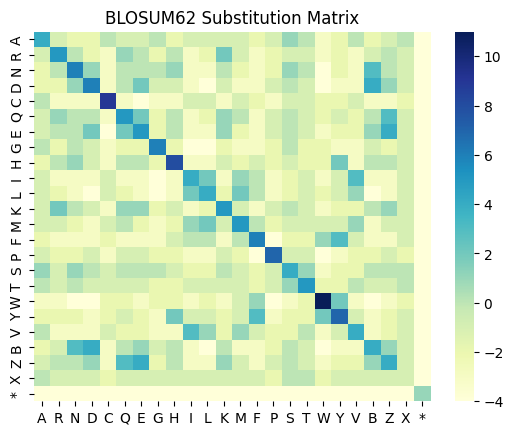

Highest score: 11.0 for residue pair (W, W)
Lowest score: -4.0 for residue pair (A, *)


In [ ]:
from Bio.Align import substitution_matrices
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

pam30 = substitution_matrices.load("PAM30")
pam250 = substitution_matrices.load("PAM250")
blosum45 = substitution_matrices.load("BLOSUM45")
blosum62 = substitution_matrices.load("BLOSUM62")
blosum80 = substitution_matrices.load("BLOSUM80")

alphabet = blosum62.alphabet
sns.heatmap(blosum62, cmap="YlGnBu", fmt="d", xticklabels=list(alphabet), yticklabels=list(alphabet))
plt.title("BLOSUM62 Substitution Matrix")
plt.show()

matrix_arr = np.array(blosum62)
max_idx = np.unravel_index(np.argmax(matrix_arr), matrix_arr.shape)
min_idx = np.unravel_index(np.argmin(matrix_arr), matrix_arr.shape)

print(f"Highest score: {matrix_arr[max_idx]} for residue pair ({alphabet[max_idx[0]]}, {alphabet[max_idx[1]]})")
print(f"Lowest score: {matrix_arr[min_idx]} for residue pair ({alphabet[min_idx[0]]}, {alphabet[min_idx[1]]})")

(b) Implement the Needleman - Wunsch global alignment algorithm using a selected substitution
matrix and a simple linear gap penalty of −2. Align human HBB and human HBA using all five matrices. Compare the alignment scores and percentage identity.

In [ ]:
import numpy as np

def needleman_wunch_subs(seq1, seq2, substitution_matrix, GAP):
    m,n = len(seq1), len(seq2)

    # Initialise score matrix
    T = np.zeros((m + 1, n + 1), dtype=int)

    # Store traceback directions
    traceback = np.zeros((m + 1, n + 1), dtype=int)

    # Direction codes: 1 = diagonal, 2 = up, 3 = left
    for i in range(1, m + 1):
        T[i, 0] = i * GAP
        traceback[i, 0] = 2
    for j in range(1, n + 1):
        T[0, j] = j * GAP
        traceback[0, j] = 3

    # Fill in the DP table
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            diagonal = T[i-1, j-1] + (substitution_matrix[seq1[i-1], seq2[j-1]])
            up = T[i-1, j] + GAP
            left = T[i, j-1] + GAP

            T[i, j] = max(diagonal, up, left)

            # Store one optimal direction
            if T[i, j] == diagonal:
                traceback[i, j] = 1
            elif T[i, j] == up:
                traceback[i, j] = 2
            else:
                traceback[i, j] = 3

    # Traceback
    aligned1, aligned2 = [], []
    score = T[m, n]
    i, j = m, n

    while i > 0 or j > 0:
        direction = traceback[i, j]

        if i > 0 and j > 0 and direction == 1:
            aligned1.append(seq1[i - 1])
            aligned2.append(seq2[j - 1])
            i -= 1
            j -= 1

        elif i > 0 and (j == 0 or direction == 2):
            aligned1.append(seq1[i - 1])
            aligned2.append("-")
            i -= 1

        else:
            aligned1.append("-")
            aligned2.append(seq2[j - 1])
            j -= 1

    aligned1 = "".join(reversed(aligned1))
    aligned2 = "".join(reversed(aligned2))

    return T, traceback, aligned1, aligned2, score

In [ ]:
human_hbb = sequence['HBB_HUMAN']
human_hba = sequence['HBA_HUMAN']
GAP = -2

substitutions = {
    "PAM30": pam30,
    "PAM250": pam250,
    "BLOSUM45": blosum45,
    "BLOSUM62": blosum62,
    "BLOSUM80": blosum80
}

results = []

for name,substitution_matrix in substitutions.items():
  T, traceback, aligned1, aligned2, score = needleman_wunch_subs(human_hbb, human_hba, substitution_matrix, GAP)

  identical = sum(x == y and x != "-" for x, y in zip(aligned1, aligned2))
  identity = 100 * (identical) / len(aligned1)

  results.append({
    "substitution matrix": name,
    "Alignment Score": score,
    "Identity (%)": round(identity, 2),
  })

alignment_df = pd.DataFrame(results)
print("Alignment of Human HBB and Human HBA")
alignment_df

Alignment of Human HBB and Human HBA


,substitution matrix,Alignment Score,Identity (%)
0,PAM30,367,41.86
1,PAM250,380,43.71
2,BLOSUM45,405,43.71
3,BLOSUM62,320,44.00
4,BLOSUM80,519,44.30


(c) Using BLOSUM62, align human HBB with human HBA, gorilla HBB and human myoglobin. Compare their alignment scores and percentage identities.

In [ ]:
hbb_human = sequence['HBB_HUMAN']
sequences = {
    "HBA_HUMAN": sequence['HBA_HUMAN'],
    "HBB_GORGO": sequence['HBB_GORGO'],
    "MB_HUMAN": sequence['MB_HUMAN']
}

results = []

for name,seq in sequences.items():
  T, traceback, aligned1, aligned2, score = needleman_wunch_subs(hbb_human, seq, blosum62, GAP)

  identical = sum(x == y and x != "-" for x, y in zip(aligned1, aligned2))
  identity = 100 * (identical) / len(aligned1)

  results.append({
    "Sequence": name,
    "Alignment Score": score,
    "Identity (%)": round(identity, 2),
  })

alignment_df = pd.DataFrame(results)
print("Alignment of Human HBB with other sequences")
alignment_df

Alignment of Human HBB with other sequences


,Sequence,Alignment Score,Identity (%)
0,HBA_HUMAN,320,44.00
1,HBB_GORGO,777,99.32
2,MB_HUMAN,179,28.74


(d) Compare the results obtained using PAM30, PAM250, BLOSUM45, BLOSUM62 and
BLOSUM80 for human HBB versus gorilla HBB and human HBB versus human myoglobin.
Identify which matrices produce the best alignments for each pair and explain why.

In [ ]:
substitutions = {
    "PAM30": pam30,
    "PAM250": pam250,
    "BLOSUM45": blosum45,
    "BLOSUM62": blosum62,
    "BLOSUM80": blosum80
}

human_hbb = sequence['HBB_HUMAN']
gorilla_hbb = sequence['HBB_GORGO']
mb_human = sequence['MB_HUMAN']

results_1 = []
results_2 = []

for name,substitution_matrix in substitutions.items():
  T, traceback, aligned1, aligned2, score = needleman_wunch_subs(human_hbb, gorilla_hbb, substitution_matrix, GAP)
  results_1.append({
    "substitution matrix": name,
    "Alignment Score": score,
  })

  T, traceback, aligned1, aligned2, score = needleman_wunch_subs(human_hbb, mb_human, substitution_matrix, GAP)
  results_2.append({
    "substitution matrix": name,
    "Alignment Score": score,
  })


df_1 = pd.DataFrame(results_1)
df_2 = pd.DataFrame(results_2)

print("Alignment of Human HBB with Gorilla HBB")
display(df_1)
print("\nAlignment of Human HBB with Human MB")
display(df_2)


# Alignment of Human HBB with Gorilla HBB
# Best alignment is produced by BLOSUM80

# Alignment of Human HBB with Human MB
# Best alignment is produced by BLOSUM80

Alignment of Human HBB with Gorilla HBB


,substitution matrix,Alignment Score
0,PAM30,1091
1,PAM250,728
2,BLOSUM45,931
3,BLOSUM62,777
4,BLOSUM80,1252



Alignment of Human HBB with Human MB


,substitution matrix,Alignment Score
0,PAM30,190
1,PAM250,236
2,BLOSUM45,250
3,BLOSUM62,179
4,BLOSUM80,330


(e) For human HBB and human HBA, compare the substitution scores of selected identical and non-identical amino acid pairs using PAM30, PAM250, BLOSUM45, BLOSUM62 and BLOSUM80. Identify residue pairs whose scores vary significantly across matrices and explain how these differences affect the final alignment score.

In [ ]:
import pandas as pd

matrices = {
    "PAM30": pam30,
    "PAM250": pam250,
    "BLOSUM45": blosum45,
    "BLOSUM62": blosum62,
    "BLOSUM80": blosum80
}

names = list(matrices.keys())

# Identical and non-identical pairs
pairs = [("A", "A"), ("W", "W"), ("A", "G"), ("D", "E")]

rows = []
for a, b in pairs:
    row = {"Residue Pair": a + "-" + b}
    for name in names:
        row[name] = matrices[name][a, b]
    rows.append(row)

df = pd.DataFrame(rows)
df["Variation"] = df[names].max(axis=1) - df[names].min(axis=1)
df.sort_values("Variation", ascending=False)

,Residue Pair,PAM30,PAM250,BLOSUM45,BLOSUM62,BLOSUM80,Variation
1,W-W,13.0,17.0,15.0,11.0,16.0,6.0
0,A-A,6.0,2.0,5.0,4.0,7.0,5.0
2,A-G,-2.0,1.0,0.0,0.0,0.0,3.0
3,D-E,2.0,3.0,2.0,2.0,2.0,1.0


In [ ]:
res = []

for name in names:
    T, traceback, a1, a2, score = needleman_wunch_subs(human_hba, human_hbb, matrices[name], GAP)
    res.append({
      "substitution matrix": name,
      "Alignment Score": score,
    })

df = pd.DataFrame(res)
df

,substitution matrix,Alignment Score
0,PAM30,367
1,PAM250,380
2,BLOSUM45,405
3,BLOSUM62,320
4,BLOSUM80,519


#Q5

(a) Use HBB_HUMAN as the reference. Align each of the other six globins to it with your Needleman–Wunsch code (match = +1, mismatch = −1, gap = −1). Keep only the columns where HBB_HUMAN has a residue, so all seven sequences form a multiple alignment with 147 columns. Print the alignment in blocks of 60 columns and count how many columns are fully conserved.

In [ ]:
globins = ["HBB_HUMAN", "HBA_HUMAN", "MB_HUMAN","MB_PHYMC","HBB_MOUSE","HBB_GORGO","HBB_HORSE"]

MATCH = 1
MISMATCH = -1
GAP = -1

multiple_alignment = {}

for name in globins:
  T, traceback, aligned_ref, aligned_seq, score = needleman_wunch(sequence['HBB_HUMAN'], sequence[name], MATCH, MISMATCH, GAP)

  filtered_seq = "".join(
      residue
      for ref_residue, residue in zip(aligned_ref, aligned_seq)
      if ref_residue != "-"
    )

  multiple_alignment[name] = filtered_seq

multiple_alignment

{'HBB_HUMAN': 'MVHLTPEEKSAVTALWGKVNVDEVGGEALGRLLVVYPWTQRFFESFGDLSTPDAVMGNPKVKAHGKKVLGAFSDGLAHLDNLKGTFATLSELHCDKLHVDPENFRLLGNVLVCVLAHHFGKEFTPPVQAAYQKVVAGVANALAHKYH',
 'HBA_HUMAN': 'MV-LSPADKTNVKAAWGKVHAGEYGAEALERFL-SFPTTKTYFPHF-DLS-----HGSAQVKGHGKKVADALTNAVAHDDNL---SA-LSDLHAHKLRVDPVNFKLLHCLLV-TLAAHLPAEFTPAVHASLDKFLASVSTVLTSKYR',
 'MB_HUMAN': 'M-GLSDGEWQLVLNVWGKVEADIPGGEVLIRLFKGHPETLEKFDKFKHLS-ED-EMASEDLKKHGATVLTA--LG-GIL-KKKGHEAPLAQSHATK-HKIP--VKYLEFISECVLSKHPG-DFGADAQAAFRKDMASNYKEL-GFQG',
 'MB_PHYMC': 'MV-L-SEEWQLVLHVWAKVEAD-VGGDILIRLFKSHPETLEKFDRFKHLKT-EAEMASEDLKKHGVTVLTA--LG-AIL-KKKGHEAELKPLHATK-HKIPE-F--ISEAIIHVL-HHPG-DFGADAQGAMNKELFRKDIA-AYKYG',
 'HBB_MOUSE': 'MVHLTDAEKAAVSCLWGKVNSDEVGGEALGRLLVVYPWTQRYFDSFGDLSSASAIMGNAKVKAHGKKVITAFNDGLNHLDSLKGTFASLSELHCDKLHVDPENFRLLGNMIVIVLGHHLGKDFTPAAQAAFQKVVAGVATALAHKYH',
 'HBB_GORGO': 'MVHLTPEEKSAVTALWGKVNVDEVGGEALGRLLVVYPWTQRFFESFGDLSTPDAVMGNPKVKAHGKKVLGAFSDGLAHLDNLKGTFATLSELHCDKLHVDPENFKLLGNVLVCVLAHHFGKEFTPPVQAAYQKVVAGVANALAHKYH',
 'HBB_HORSE'

In [ ]:
# Print alignment in blocks of 60 columns
block_size = 60
names = list(multiple_alignment.keys())

for start in range(0, 147, block_size):
    end = min(start + block_size, 147)
    print(f"\nColumns {start + 1}-{end}")
    for name in names:
        print(f"{name:20s} {multiple_alignment[name][start:end]}")
    print()


Columns 1-60
HBB_HUMAN            MVHLTPEEKSAVTALWGKVNVDEVGGEALGRLLVVYPWTQRFFESFGDLSTPDAVMGNPK
HBA_HUMAN            MV-LSPADKTNVKAAWGKVHAGEYGAEALERFL-SFPTTKTYFPHF-DLS-----HGSAQ
MB_HUMAN             M-GLSDGEWQLVLNVWGKVEADIPGGEVLIRLFKGHPETLEKFDKFKHLS-ED-EMASED
MB_PHYMC             MV-L-SEEWQLVLHVWAKVEAD-VGGDILIRLFKSHPETLEKFDRFKHLKT-EAEMASED
HBB_MOUSE            MVHLTDAEKAAVSCLWGKVNSDEVGGEALGRLLVVYPWTQRYFDSFGDLSSASAIMGNAK
HBB_GORGO            MVHLTPEEKSAVTALWGKVNVDEVGGEALGRLLVVYPWTQRFFESFGDLSTPDAVMGNPK
HBB_HORSE            -VQLSGEEKAAVLALWDKVNEEEVGGEALGRLLVVYPWTQRFFDSFGDLSNPGAVMGNPK


Columns 61-120
HBB_HUMAN            VKAHGKKVLGAFSDGLAHLDNLKGTFATLSELHCDKLHVDPENFRLLGNVLVCVLAHHFG
HBA_HUMAN            VKGHGKKVADALTNAVAHDDNL---SA-LSDLHAHKLRVDPVNFKLLHCLLV-TLAAHLP
MB_HUMAN             LKKHGATVLTA--LG-GIL-KKKGHEAPLAQSHATK-HKIP--VKYLEFISECVLSKHPG
MB_PHYMC             LKKHGVTVLTA--LG-AIL-KKKGHEAELKPLHATK-HKIPE-F--ISEAIIHVL-HHPG
HBB_MOUSE            VKAHGKKVITAFNDGLNHLDSLKGTFASLSELHCDKLHVDPENFRL

In [ ]:
aligned_sequences = list(multiple_alignment.values())

fully_conserved = 0
conserved_positions = []

for col in range(147):
    residues = [seq[col] for seq in aligned_sequences]
    if "-" not in residues and len(set(residues)) == 1:
        fully_conserved += 1
        conserved_positions.append(col + 1)

print("Total alignment columns:", 147)
print("Fully conserved columns:", fully_conserved)
print("Conserved positions:", conserved_positions)
print("Percentage conserved:", round(fully_conserved / 147 * 100, 2), "%")

Total alignment columns: 147
Fully conserved columns: 26
Conserved positions: [4, 12, 16, 18, 19, 25, 29, 31, 37, 39, 43, 46, 49, 62, 64, 65, 68, 87, 89, 93, 96, 101, 115, 118, 123, 133]
Percentage conserved: 17.69 %


(b) For each column, count the residues and convert the counts to frequencies p(i, j). Add a pseudocount of 1 for every residue type so that no frequency is zero. Ignore gap characters
when counting.

In [ ]:
from collections import Counter

column_frequencies = []
standard_amino_acids = "ACDEFGHIKLMNPQRSTVWY"

for col in range(147):
    # Count residues, ignoring gaps
    residues = [seq[col] for seq in multiple_alignment.values()
                if seq[col] != "-"]
    counts = Counter(residues)

    # Add pseudocount of 1 and calculate frequencies
    frequencies = {}
    for aa in standard_amino_acids:
        frequencies[aa] = (counts[aa] + 1) / (len(residues) + 20)

    column_frequencies.append(frequencies)


# Print frequencies for the first 5 columns
for col in range(5):
    print(f"\nColumn {col + 1}")
    print(column_frequencies[col])


Column 1
{'A': 0.038461538461538464, 'C': 0.038461538461538464, 'D': 0.038461538461538464, 'E': 0.038461538461538464, 'F': 0.038461538461538464, 'G': 0.038461538461538464, 'H': 0.038461538461538464, 'I': 0.038461538461538464, 'K': 0.038461538461538464, 'L': 0.038461538461538464, 'M': 0.2692307692307692, 'N': 0.038461538461538464, 'P': 0.038461538461538464, 'Q': 0.038461538461538464, 'R': 0.038461538461538464, 'S': 0.038461538461538464, 'T': 0.038461538461538464, 'V': 0.038461538461538464, 'W': 0.038461538461538464, 'Y': 0.038461538461538464}

Column 2
{'A': 0.038461538461538464, 'C': 0.038461538461538464, 'D': 0.038461538461538464, 'E': 0.038461538461538464, 'F': 0.038461538461538464, 'G': 0.038461538461538464, 'H': 0.038461538461538464, 'I': 0.038461538461538464, 'K': 0.038461538461538464, 'L': 0.038461538461538464, 'M': 0.038461538461538464, 'N': 0.038461538461538464, 'P': 0.038461538461538464, 'Q': 0.038461538461538464, 'R': 0.038461538461538464, 'S': 0.038461538461538464, 'T': 0.0

(c) Build the PSSM using S(i, j) = log2(p(i, j) / q(i)), where q(i) = 0.05 for all 20 amino acids. Print the scores for the first 5 columns.

In [ ]:
import math

pssm = []

for col in range(147):
    scores = {}
    for aa in standard_amino_acids:
        p = column_frequencies[col][aa]
        scores[aa] = math.log2(p / 0.05)
    pssm.append(scores)

# Print scores for the first 5 columns
for col in range(5):
    print(f"\nColumn {col + 1}")
    print(pssm[col])


Column 1
{'A': -0.3785116232537297, 'C': -0.3785116232537297, 'D': -0.3785116232537297, 'E': -0.3785116232537297, 'F': -0.3785116232537297, 'G': -0.3785116232537297, 'H': -0.3785116232537297, 'I': -0.3785116232537297, 'K': -0.3785116232537297, 'L': -0.3785116232537297, 'M': 2.428843298803874, 'N': -0.3785116232537297, 'P': -0.3785116232537297, 'Q': -0.3785116232537297, 'R': -0.3785116232537297, 'S': -0.3785116232537297, 'T': -0.3785116232537297, 'V': -0.3785116232537297, 'W': -0.3785116232537297, 'Y': -0.3785116232537297}

Column 2
{'A': -0.3785116232537297, 'C': -0.3785116232537297, 'D': -0.3785116232537297, 'E': -0.3785116232537297, 'F': -0.3785116232537297, 'G': -0.3785116232537297, 'H': -0.3785116232537297, 'I': -0.3785116232537297, 'K': -0.3785116232537297, 'L': -0.3785116232537297, 'M': -0.3785116232537297, 'N': -0.3785116232537297, 'P': -0.3785116232537297, 'Q': -0.3785116232537297, 'R': -0.3785116232537297, 'S': -0.3785116232537297, 'T': -0.3785116232537297, 'V': 2.42884329880


(d) Compute the information content of each column, R_c = log2 20 − H_c, and plot it against column position. Report the three most conserved columns.


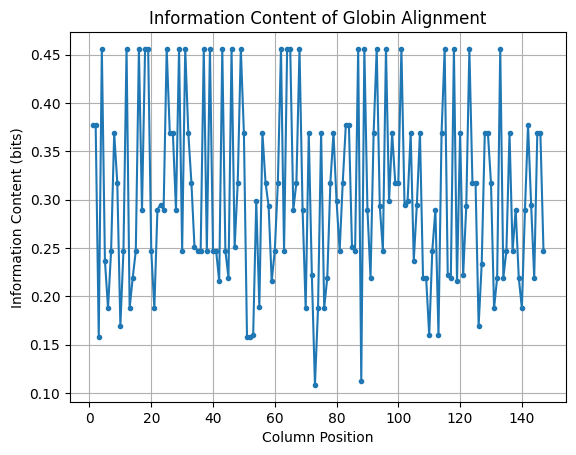

Three most conserved columns:
Column: 12 Information content: 0.4559
Column: 16 Information content: 0.4559
Column: 19 Information content: 0.4559


In [ ]:
import math
import matplotlib.pyplot as plt

information = []

for col in range(147):
    entropy = 0

    for aa in standard_amino_acids:
        p = column_frequencies[col][aa]
        entropy = entropy - p * math.log2(p)

    R = math.log2(20) - entropy
    information.append(R)

# Plot information content
plt.plot(range(1, 148), information, marker='.')
plt.xlabel("Column Position")
plt.ylabel("Information Content (bits)")
plt.title("Information Content of Globin Alignment")
plt.grid()
plt.show()

# Find the three most conserved columns
top_three = sorted(range(147),
                   key=lambda col: information[col],
                   reverse=True)[:3]

print("Three most conserved columns:")
for col in top_three:
    print("Column:", col + 1,
          "Information content:", round(information[col], 4))

(e) Score each of the seven aligned sequences against the PSSM by summing S(i, j) over its non-gap columns. Rank the sequences by score. Say which scores highest and which lowest, and whether the ranking fits what you know about how closely related the proteins are.

In [ ]:
sequence_scores = {}

for name, seq in multiple_alignment.items():
    total = 0

    for col in range(147):
        aa = seq[col]

        if aa != "-":
            total += pssm[col][aa]

    sequence_scores[name] = total

# Rank sequences from highest to lowest score
ranking = sorted(sequence_scores.items(),
                 key=lambda x: x[1],
                 reverse=True)

print("Sequence ranking:")
for name, score in ranking:
    print(name, round(score, 3))

Sequence ranking:
HBB_HUMAN 305.841
HBB_GORGO 305.841
HBB_MOUSE 288.139
HBB_HORSE 285.926
MB_PHYMC 211.222
HBA_HUMAN 210.299
MB_HUMAN 207.588


(f) In two or three sentences, explain what a positive score and a negative score mean in a PSSM.

In [ ]:
# A positive PSSM score indicates that an amino acid occurs more frequently at a particular alignment position than expected
# from its background probability of 0.05. A negative PSSM score indicates that the amino acid occurs less frequently than expected,
# while a score of zero means its frequency equals the background probability.